Entrenando LSTM avanzada multivariada...
Epoch 1/15


d:\Datos\tensorflow\tf-env-312\Lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


55/55 ━━━━━━━━━━━━━━━━━━━━ 3s 12ms/step - loss: 0.0490 - val_loss: 0.0192
Epoch 2/15
55/55 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0224 - val_loss: 0.0160
Epoch 3/15
55/55 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0181 - val_loss: 0.0132
Epoch 4/15
55/55 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0140 - val_loss: 0.0104
Epoch 5/15
55/55 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0105 - val_loss: 0.0072
Epoch 6/15
55/55 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0092 - val_loss: 0.0065
Epoch 7/15
55/55 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0081 - val_loss: 0.0064
Epoch 8/15
55/55 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0075 - val_loss: 0.0075
Epoch 9/15
55/55 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0068 - val_loss: 0.0052
Epoch 10/15
55/55 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.0065 - val_loss: 0.0068
Epoch 11/15
55/55 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0064 - val_loss: 0.0047
Epoch 12/15
55/55 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0058 - val_loss: 0.0044

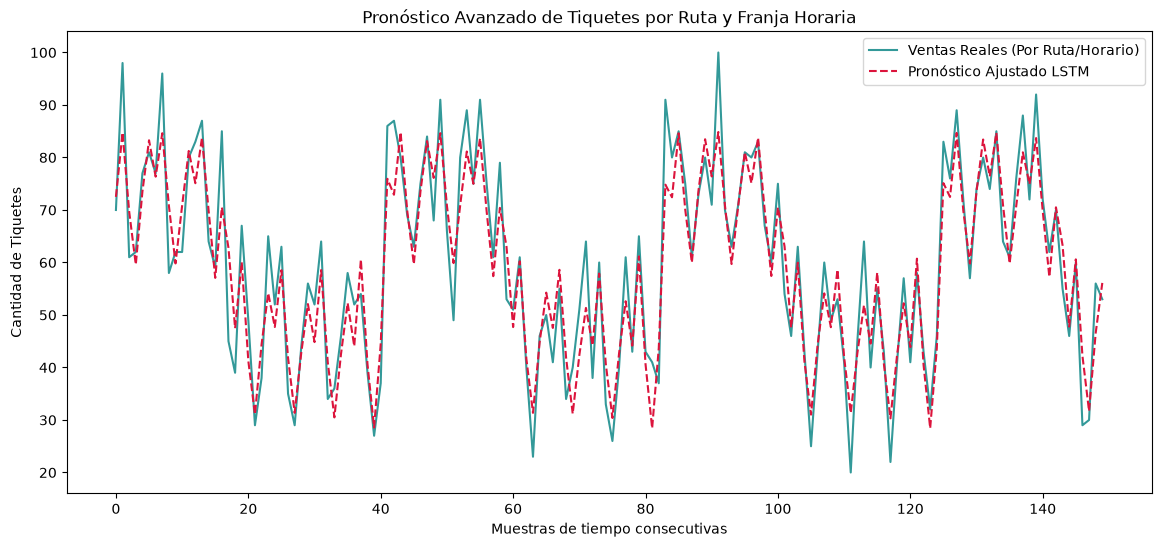

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout

# ==========================================
# 1. SIMULACIÓN DE DATASET MULTIVARIADO
# ==========================================
np.random.seed(42)

# Definimos nuestras dimensiones de negocio
rutas = ['Bogota-Medellin', 'Cali-Bogota']
horarios = ['Mañana', 'Tarde', 'Noche']
fechas = pd.date_range(start="2024-01-01", end="2025-12-31", freq="D")

lista_datos = []
for fecha in fechas:
    for ruta in rutas:
        for horario in horarios:
            # Base de ventas según la ruta y el horario
            base = 40 if ruta == 'Bogota-Medellin' else 25
            modificador_horario = 15 if horario == 'Mañana' else (5 if horario == 'Tarde' else 20)
            
            # Estacionalidad de fin de semana (Viernes=4, Sábado=5, Domingo=6)
            fin_de_semana = 30 if fecha.weekday() in [4, 5, 6] else 0
            
            # Ruido aleatorio normal del mercado
            ruido = np.random.normal(0, 5)
            
            ventas = max(0, int(base + modificador_horario + fin_de_semana + ruido))
            
            lista_datos.append({
                'Fecha': fecha,
                'Ruta': ruta,
                'Horario': horario,
                'Dia_Semana': fecha.weekday(),
                'Mes': fecha.month,
                'Ventas': ventas
            })

df = pd.DataFrame(lista_datos)

# ==========================================
# 2. PREPROCESAMIENTO Y VARIABLES (FEATURES)
# ==========================================
# Convertimos las columnas de texto (Ruta y Horario) en columnas numéricas binarias (One-Hot)
df_procesado = pd.get_dummies(df, columns=['Ruta', 'Horario', 'Dia_Semana', 'Mes'], dtype=int)

# Reorganizamos para que 'Ventas' quede al final y sea fácil de aislar
columnas = [col for col in df_procesado.columns if col not in ['Fecha', 'Ventas']] + ['Ventas']
df_final = df_procesado[columnas]

# Normalizamos todas las variables entre 0 y 1 para mejorar la convergencia de la red
scaler = MinMaxScaler(feature_range=(0, 1))
datos_escalados = scaler.fit_transform(df_final)

# ==========================================
# 3. CREACIÓN DE VENTANAS TEMPORALES
# ==========================================
# Usaremos los últimos 14 registros históricos de esa combinación para predecir el siguiente
def crear_ventanas_multivariadas(datos, ventana_tiempo=14):
    X, y = [], []
    for i in range(len(datos) - ventana_tiempo):
        X.append(datos[i:(i + ventana_tiempo), :]) # Todas las variables de los últimos 14 pasos
        y.append(datos[i + ventana_tiempo, -1])     # Solo la columna 'Ventas' del paso 15
    return np.array(X), np.array(y)

ventana = 14
X, y = crear_ventanas_multivariadas(datos_escalados, ventana)

# Dividir en Entrenamiento (80%) y Validación (20%)
limite = int(len(X) * 0.8)
X_train, X_test = X[:limite], X[limite:]
y_train, y_test = y[:limite], y[limite:]

# ==========================================
# 4. MODELO DE RED NEURONAL LSTM PROFUNDA
# ==========================================
model = Sequential([
    # Primera capa LSTM (Retorna secuencias para alimentar a la siguiente LSTM)
    LSTM(units=64, return_sequences=True, input_shape=(X.shape[1], X.shape[2])),
    Dropout(0.2), # Evita el sobreajuste apagando neuronas al azar
    
    # Segunda capa LSTM
    LSTM(units=32, return_sequences=False),
    Dropout(0.2),
    
    # Capa Densa Intermedia
    Dense(units=16, activation='relu'),
    
    # Capa de salida (un único valor de ventas continuas)
    Dense(units=1)
])

# Compilación utilizando el optimizador Adam
model.compile(optimizer='adam', loss='mean_squared_error')

# ==========================================
# 5. ENTRENAMIENTO
# ==========================================
print("Entrenando LSTM avanzada multivariada...")
historial = model.fit(
    X_train, y_train, 
    epochs=15, 
    batch_size=64, 
    validation_data=(X_test, y_test), 
    verbose=1
)

# ==========================================
# 6. PREDICCIÓN Y DES-ESCALADO (Invertir escala)
# ==========================================
predicciones = model.predict(X_test)

# Para des-escalar de forma exacta, creamos una matriz espejo del tamaño original
matriz_espejo_pred = np.zeros((len(predicciones), datos_escalados.shape[1]))
matriz_espejo_pred[:, -1] = predicciones.flatten()
predicciones_reales = scaler.inverse_transform(matriz_espejo_pred)[:, -1]

matriz_espejo_test = np.zeros((len(y_test), datos_escalados.shape[1]))
matriz_espejo_test[:, -1] = y_test
y_test_real = scaler.inverse_transform(matriz_espejo_test)[:, -1]

# ==========================================
# 7. GRAFICAR RESULTADOS (Muestra de los primeros 150 registros del set de prueba)
# ==========================================
plt.figure(figsize=(14, 6))
plt.plot(y_test_real[:150], label="Ventas Reales (Por Ruta/Horario)", color="teal", alpha=0.8)
plt.plot(predicciones_reales[:150], label="Pronóstico Ajustado LSTM", color="crimson", linestyle="--")
plt.title("Pronóstico Avanzado de Tiquetes por Ruta y Franja Horaria")
plt.ylabel("Cantidad de Tiquetes")
plt.xlabel("Muestras de tiempo consecutivas")
plt.legend()
plt.show()
